# Prostate cancer

This notebook reproduces results of the prostate cancer model of
[Montagud et al. (eLife, 2022)](https://doi.org/10.7554/eLife.72626), on the [MaBoSS website](https://maboss.curie.fr).
It is adapted from the [pyMaBoSS tutorial](https://pymaboss.readthedocs.io/en/latest/notebooks/Reproducing_Prostate_Montagud.html).

The model describes the signaling pathways involved in prostate cancer. With 133 nodes, it is a large model:
it requires an executable of MaBoSS supporting more than 128 nodes, such as `MaBoSS_256n`, which is provided by
the conda package of pyMaBoSS. Without any mutation, it can be considered as a model of healthy prostate cells
(the wild type model). The model was then personalized to the data of patients and cell lines.

**Requirements:** [pyMaBoSS](https://pymaboss.readthedocs.io/), the files `Montagud2022_Prostate_Cancer.bnd` and
`Montagud2022_Prostate_Cancer.cfg`, and the folder `patient_models`, in the same folder as this notebook.

In [1]:
import math
import os
import maboss
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.offsetbox import HPacker

# The figures are saved in the "figures" folder
os.makedirs("figures", exist_ok=True)
plt.rcParams.update({"savefig.dpi": 150, "savefig.bbox": "tight", "figure.constrained_layout.use": True})

def legend_below():
    """Move the legend of the current figure below the plot, in centered rows of similar widths."""
    figure, legend = plt.gcf(), plt.gca().get_legend()
    handles, labels = legend.legend_handles, [text.get_text() for text in legend.get_texts()]
    legend.remove()
    legend = figure.legend(handles, labels, loc="outside lower center", ncols=1)
    # Matplotlib fills the rows from the left: we rearrange the entries of the legend in centered rows,
    # as few as possible within the width of the plot, and of similar widths
    column = legend._legend_handle_box.get_children()[0]
    entries, column.align = column.get_children(), "center"
    sep = legend.columnspacing * legend.prop.get_size_in_points() * figure.dpi / 72
    widths = [entry.get_bbox(figure.canvas.get_renderer()).width + sep for entry in entries]
    max_width = 0.8 * figure.get_figwidth() * figure.dpi
    for n_rows in range(math.ceil(sum(widths) / max_width), len(entries) + 1):
        rows, row_widths = [[]], [0]
        for entry, width in zip(entries, widths):
            if rows[-1] and row_widths[-1] + width / 2 > sum(widths) / n_rows:
                rows.append([])
                row_widths.append(0)
            rows[-1].append(entry)
            row_widths[-1] += width
        if max(row_widths) <= max_width:
            break
    column._children = [HPacker(sep=sep, align="baseline", children=row) for row in rows]

## The model

The output nodes are the three phenotypes: Apoptosis, Metastasis and Proliferation.

In [2]:
model = maboss.load("Montagud2022_Prostate_Cancer.bnd", "Montagud2022_Prostate_Cancer.cfg")
print(len(model.network), "nodes")
print("Output nodes:", ", ".join(n for n in model.network if not model.network[n].is_internal))

133 nodes
Output nodes: Apoptosis, Metastasis, Proliferation


## Default simulation

In the configuration file, the inputs of the model are random: the simulation explores all the combinations of
inputs, and thus all the possible phenotypes.

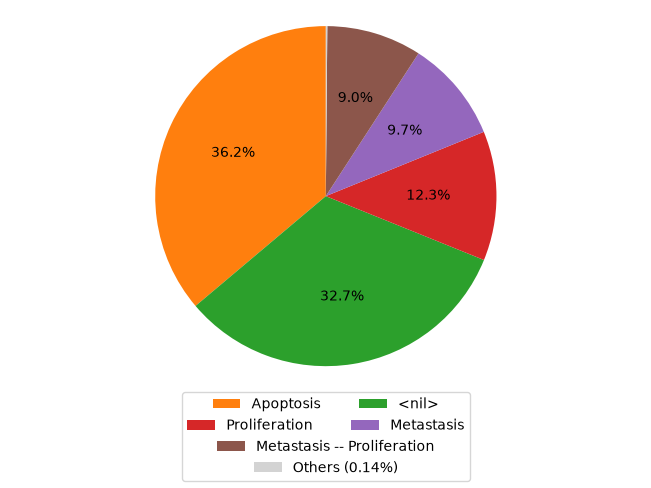

In [3]:
result_default = model.run()
result_default.plot_piechart()
legend_below()
plt.savefig("figures/prostate_default.png")

## Healthy cells

In the article, *"these healthy cells mostly exhibit quiescence (neither proliferation nor apoptosis) in the
absence of any input"* (Figure 3A). We set all the inputs to 0.

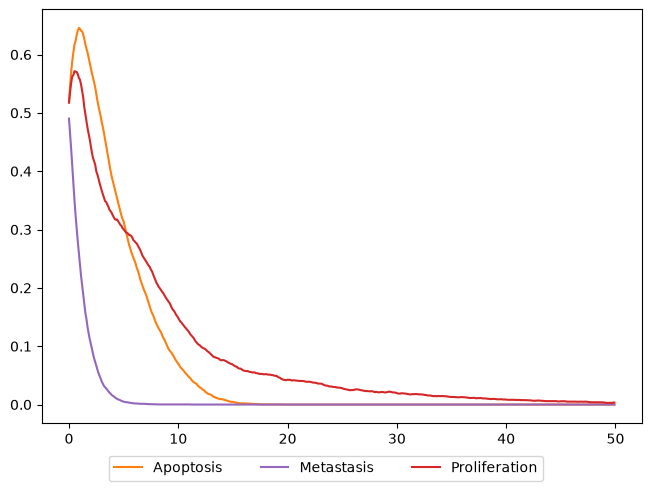

In [4]:
inputs = ["EGF", "FGF", "Androgen", "TGFb", "Hypoxia", "Nutrients", "Carcinogen", "fused_event", "Acidosis",
          "SPOP", "TNFalpha"]

model_healthy = model.copy()
for node in inputs:
    model_healthy.network.set_istate(node, [1, 0])
result_healthy = model_healthy.run()
result_healthy.plot_node_trajectory()
legend_below()
plt.savefig("figures/prostate_healthy.png")

## Comparing several simulations

To compare several simulations on the same figure, we plot their final states as stacked bars, with pandas.
`<nil>` is the state where no phenotype is active. Each state keeps the same color in all the figures.

In [5]:
colors = {}

def plot_final_states(results, title):
    table = pd.concat({name: result.get_last_states_probtraj().iloc[0] for name, result in results.items()}, axis=1)
    color = [colors.setdefault(state, f"C{len(colors) % 10}") for state in table.index]
    table.T.fillna(0).plot.barh(stacked=True, color=color, title=title, xlim=(0, 1))
    plt.xlabel("Probability")
    plt.gca().invert_yaxis()
    legend_below()

## Growth condition and MYC_MAX inhibition

*"When Nutrients and growth factors (EGF or FGF) are present, Proliferation is activated"*. We activate EGF and
Nutrients, and simulate the inhibition of MYC_MAX, which blocks proliferation (Appendix 1, figure 34).

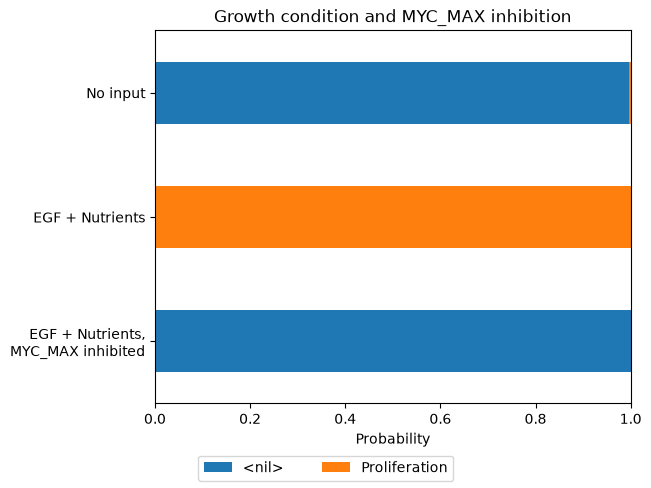

In [6]:
model_growth = model_healthy.copy()
model_growth.network.set_istate("EGF", [0, 1])
model_growth.network.set_istate("Nutrients", [0, 1])

model_growth_myc = model_growth.copy()
model_growth_myc.mutate("MYC_MAX", "OFF")

plot_final_states({
    "No input": result_healthy,
    "EGF + Nutrients": model_growth.run(),
    "EGF + Nutrients,\nMYC_MAX inhibited": model_growth_myc.run(),
}, "Growth condition and MYC_MAX inhibition")
plt.savefig("figures/prostate_growth.png")

## Single mutants

To find other mutations that reduce or block proliferation, we simulate the inhibition of several candidate
nodes, in the growth condition, with the functions of `maboss.pipelines`.

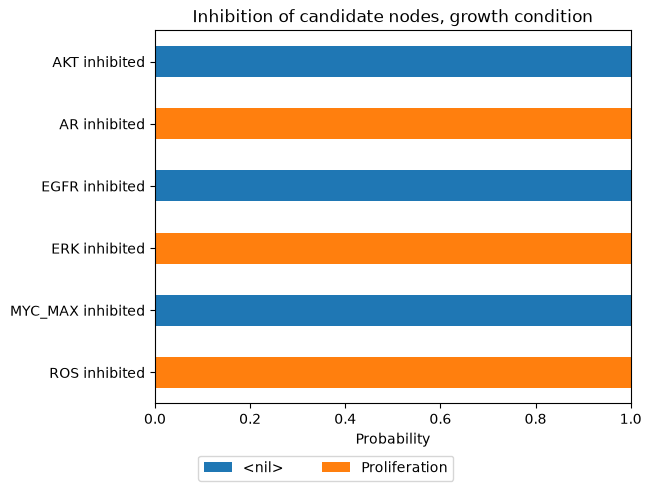

In [7]:
from maboss.pipelines import simulate_single_mutants, filter_sensitivity

candidates = ["AKT", "AR", "EGFR", "ERK", "MYC_MAX", "ROS"]
mutants = simulate_single_mutants(model_growth, candidates, "OFF")

# The results are indexed by (node, "OFF")
plot_final_states({f"{node} inhibited": result for (node, _), result in mutants.items()},
                "Inhibition of candidate nodes, growth condition")
plt.savefig("figures/prostate_mutants.png")

`filter_sensitivity` selects the mutants without any proliferation:

In [8]:
no_proliferation = filter_sensitivity(mutants, node="Proliferation", maximum=0)
print("Mutants without proliferation:", ", ".join(sorted(node for node, _ in no_proliferation)))

Mutants without proliferation: AKT, EGFR, MYC_MAX


## Personalized models

Montagud et al. personalized the model to the data of patients (TCGA) and cell lines. We use here ten of the
patient models, provided with the article. Their phenotypes vary a lot.

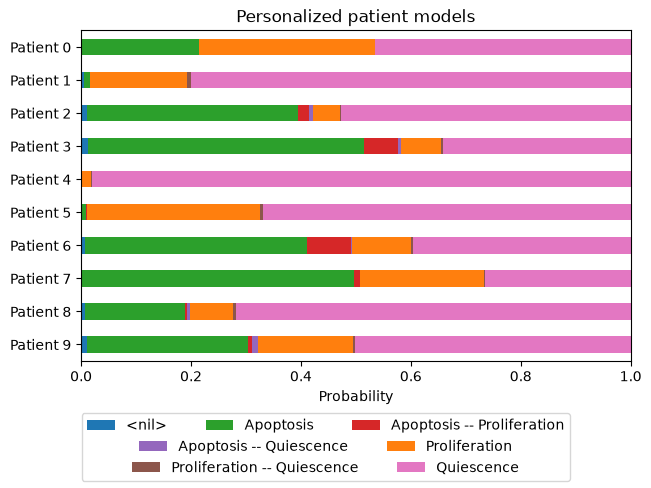

In [9]:
patients = {
    f"Patient {i}": maboss.load(f"patient_models/PC_20191219_TCGA_mutCNA_RNA_{i}.bnd",
                                f"patient_models/PC_20191219_TCGA_mutCNA_RNA_{i}.cfg")
    for i in range(10)
}
plot_final_states({name: patient.run() for name, patient in patients.items()}, "Personalized patient models")
plt.savefig("figures/prostate_patients.png")

We now simulate the growth condition with an inhibition of MYC_MAX on each personalized model.

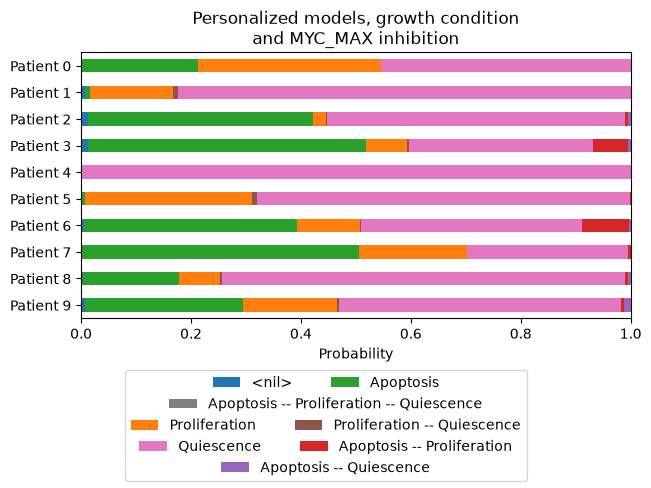

In [10]:
results_myc = {}
for name, patient in patients.items():
    patient_myc = patient.copy()
    patient_myc.network.set_istate("EGF", [0, 1])
    patient_myc.network.set_istate("Nutrients", [0, 1])
    patient_myc.mutate("MYC_MAX", "OFF")
    results_myc[name] = patient_myc.run()

plot_final_states(results_myc, "Personalized models, growth condition\nand MYC_MAX inhibition")
plt.savefig("figures/prostate_patients_myc.png")

The personalized models in which MYC_MAX inhibition reduces proliferation below 10%:

In [11]:
print(", ".join(name for name, result in results_myc.items()
                if result.get_last_nodes_probtraj().iloc[0].get("Proliferation", 0) < 0.1))

Patient 2, Patient 4, Patient 8
